# Two-phase 5,000 USD funded account: odds of passing with the automated breakout

**Rules**

| Rule | Value |
|---|---|
| Phase 1 target | +400 USD |
| Phase 2 target | +200 USD (new account) |
| Daily loss | at most 200 USD |
| Total loss | at most 400 USD, static floor at 4,600 |
| Time limit | none |
| Exposure | at most 150 USD at risk across open trades; every trade has a stop |
| News (funded phase) | gains realized within 5 minutes of a major release count 40%, losses 100% |
| Copy trading | identical trades between users and copy trading are forbidden |

Without a time limit, each phase is a race between the target and the floor. The question is
how likely the automated New York opening range breakout is to win that race, how long it
takes, and how much the risk per trade matters.

The bot's risk manager (goldbot/risk.py) sizes each trade at the configured risk, reduced to the
room left under the daily limit, the floor and the exposure cap (minus a 15 USD buffer), and
skips the trade when less than 20 USD of room is left. The simulations below use that same logic.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, "..")
import engine as E, challenge as C
from goldbot.backtest import run_backtest
from goldbot.config import Config, NewsConfig
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
m1 = E.load_m1()
os.environ["GB_ORB_SESSIONS"] = "ny_comex"

def orb_trades(news="off", risk=50.0):
    c = Config.from_env("none.env"); c.judge.enabled = False
    c.risk.risk_per_trade_usd = risk; c.risk.profit_target = 0; c.risk.max_total_loss = 0
    c.news = NewsConfig(source=news)
    return run_backtest(c, m1)["trades"]

tr = orb_trades()
days = pd.to_datetime(tr["day"])
tpd = len(tr) / np.busday_count(days.min().date(), days.max().date())
oos = pd.to_datetime(tr.entry_time) >= "2025-01-01"
print(f"{len(tr)} trades, {tpd:.2f} per trading day, mean {tr.R.mean():+.3f} R "
      f"(2022-2024 {tr.R[~oos].mean():+.3f}, 2025-2026 {tr.R[oos].mean():+.3f}), win rate {(tr.R > 0).mean():.0%}")

567 trades, 0.45 per trading day, mean +0.057 R (2022-2024 +0.058, 2025-2026 +0.057), win rate 40%


## 1. Replaying history: a new challenge started every week

In [2]:
day_index = {d: i for i, d in enumerate(sorted(days.dt.date.unique()))}
all_days = pd.Series(pd.bdate_range(days.min(), days.max()).date)
bday_id = {d: i for i, d in enumerate(all_days)}
did = np.array([bday_id[d] for d in days.dt.date])
starts = np.array(sorted({bday_id[d] for d in all_days if d.weekday() == 0}))[:-26]
rows = []
for risk in [25, 50, 75, 100, 150]:
    df = C.simulate(did, tr.R.to_numpy(), starts, risk, min_risk=20.0)
    s = C.summarize(df)
    rows.append({"risk per trade": risk, "challenges": s["starts"], "finished": s["resolved"],
                 "passed both phases": s["pass_both"], "passed phase 1": s["pass_phase1"],
                 "median business days to pass": s["median_days_to_pass"]})
hist = pd.DataFrame(rows).set_index("risk per trade")
hist.round(3)

,challenges,finished,passed both phases,passed phase 1,median business days to pass
risk per trade,,,,,
25,226,175,0.314,0.607,344.0
50,226,223,0.309,0.584,72.0
75,226,226,0.465,0.624,51.0
100,226,226,0.288,0.562,25.0
150,226,226,0.204,0.535,14.0


Each row starts one challenge every Monday from 2022 to mid 2026 and follows the real trade
sequence until both phases pass or the floor stops it. Starts overlap, so these are not
independent samples. With small risk many challenges have not finished by the end of the data.

## 2. Monte Carlo: pass odds by edge and risk

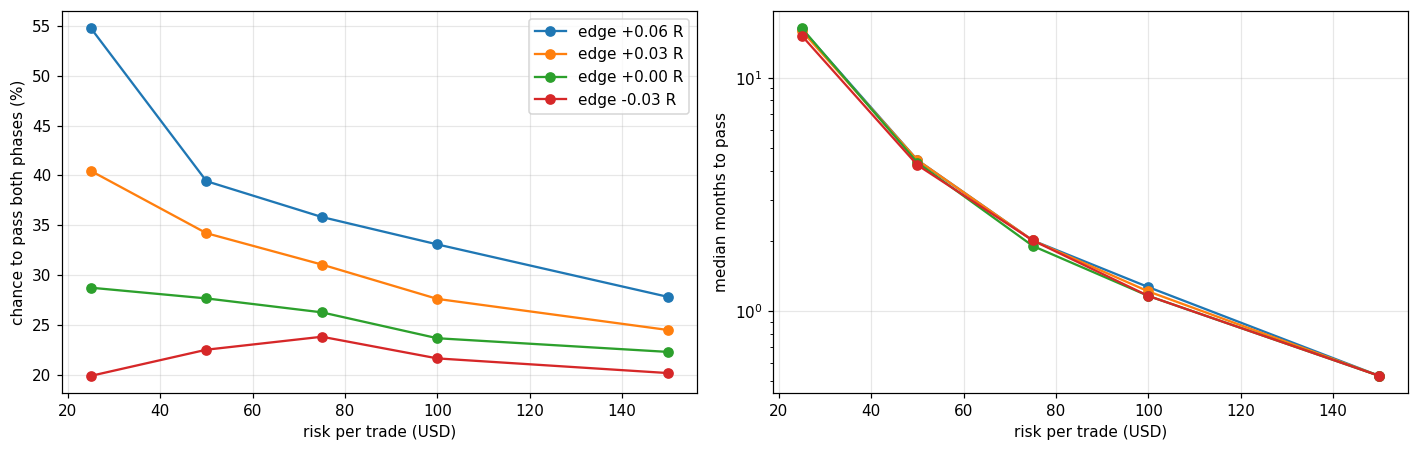

edge (R per trade),-0.03,0.00,0.03,0.06
risk,,,,
25,0.199,0.287,0.404,0.548
50,0.225,0.276,0.342,0.394
75,0.238,0.262,0.310,0.358
100,0.216,0.236,0.276,0.331
150,0.202,0.223,0.245,0.278


In [3]:
rng = np.random.default_rng(0)
N, L = 4000, 2500
base = tr.R.to_numpy()
rows = []
for edge in [0.06, 0.03, 0.0, -0.03]:
    sample = base - base.mean() + edge
    for risk in [25, 50, 75, 100, 150]:
        r = rng.choice(sample, N * L)
        df = C.simulate(np.arange(N * L), r, np.arange(N) * L, risk, min_risk=20.0)
        passed = df.result == "passed"
        rows.append({"edge (R per trade)": edge, "risk": risk, "pass": passed.mean(),
                     "fail": (df.result == "failed").mean(),
                     "median months": np.median(df.total_days[passed]) / tpd / 21 if passed.any() else np.nan})
mc = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for edge, g in mc.groupby("edge (R per trade)", sort=False):
    ax[0].plot(g.risk, g["pass"] * 100, "o-", label=f"edge {edge:+.2f} R")
    ax[1].plot(g.risk, g["median months"], "o-", label=f"edge {edge:+.2f} R")
ax[0].set_xlabel("risk per trade (USD)"); ax[0].set_ylabel("chance to pass both phases (%)"); ax[0].legend()
ax[1].set_xlabel("risk per trade (USD)"); ax[1].set_ylabel("median months to pass"); ax[1].set_yscale("log")
plt.tight_layout(); plt.show()
mc.pivot(index="risk", columns="edge (R per trade)", values="pass").round(3)

Trades are drawn from the real breakout outcomes, shifted to a chosen average edge. An edge of
+0.06 R is what the backtest measured (not statistically proven). 0 is what a coin flip with
the same payoff shape would get. Reading:

* With **no edge**, the odds of passing both phases are about 25 to 29% whatever the size.
  This is the luck baseline of a +400 / -400 race followed by a +200 / -400 race.
* With the measured **+0.06 R**, small risk helps: about 55% at 25 USD, but it takes over a
  year. 50 USD gives about 40% in about 4 months; 75 USD about 35% in about 2 months.
* Large risk (100 to 150) is fast (weeks) but the edge no longer matters: it is close to a coin flip.

In [4]:
mc.pivot(index="risk", columns="edge (R per trade)", values="median months").round(1)

edge (R per trade),-0.03,0.00,0.03,0.06
risk,,,,
25,15.1,16.3,15.9,16.2
50,4.2,4.3,4.4,4.4
75,2.0,1.9,2.0,2.0
100,1.2,1.2,1.2,1.3
150,0.5,0.5,0.5,0.5


## 3. The news rule (funded phase)

In [5]:
runs = {"no news handling": orb_trades("off"),
        "close winners before 10:00 every weekday": None}
c = Config.from_env("none.env"); c.judge.enabled = False
c.risk.risk_per_trade_usd = 50; c.risk.profit_target = 0; c.risk.max_total_loss = 0
c.news = NewsConfig(source="fixed:10:00", close_winners=True)
runs["close winners before 10:00 every weekday"] = run_backtest(c, m1)["trades"]
rows = []
for name, t in runs.items():
    ny = pd.to_datetime(t.exit_time).dt.tz_localize("UTC").dt.tz_convert("America/New_York")
    mins = ny.dt.hour * 60 + ny.dt.minute
    win = np.zeros(len(t), bool)
    for ev in (510, 600, 840):
        win |= (mins - ev).abs().to_numpy() <= 5
    counted = np.where(win & (t.pnl > 0), 0.4 * t.pnl, t.pnl)
    rows.append({"variant": name, "pnl at 50 USD risk": t.pnl.sum(),
                 "gains closed within 5 min of 08:30/10:00/14:00": t.pnl[win & (t.pnl > 0)].sum(),
                 "pnl if every such gain counted 40%": counted.sum()})
pd.DataFrame(rows).set_index("variant").round(0)

,pnl at 50 USD risk,gains closed within 5 min of 08:30/10:00/14:00,pnl if every such gain counted 40%
variant,,,
no news handling,1535.0,1277.0,769.0
close winners before 10:00 every weekday,332.0,0.0,332.0


The breakout never trades around 08:30 (its range is still forming) or 14:00 (it is flat by
12:00), but about 9% of trades close within 5 minutes of 10:00. Even in the worst case, where
every weekday had a major 10:00 release, holding and accepting the 40% haircut keeps about half
the profit, while closing winners early keeps only a fifth (it cuts the 3R winners). In reality
only some days have a major 10:00 release (ISM, JOLTS, consumer confidence and similar), so the
cost is smaller. The bot therefore blocks new setups around releases and leaves open trades alone
(GB_NEWS_CLOSE_WINNERS=false).

## Conclusions

* These rules are far more reachable than "+600 in a week": with no time limit, even a coin flip
  passes both phases about a quarter of the time.
* The automated breakout's measured +0.06 R edge, if it is real, lifts that to about 35 to 55%,
  and the smaller the risk the more the edge counts, at the cost of time.
* Recommended setting: **50 USD risk per trade** (about 40% pass in about 4 months if the edge
  holds, about 29% if it does not), or 75 USD to be faster (about 35% in about 2 months).
  Above 100 USD the strategy stops mattering.
* All rules are enforced by the bot before each order: daily 200, floor 4,600, 150 maximum open
  risk, target 400 (set GB_PROFIT_TARGET=200 for phase 2), stops on every order, news blackout.
* Do not run the same bot on several users' accounts: identical trades between users and copy
  trading are forbidden by the rules.